In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display configuration
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Load dataset
# Resolve paths from either the project root or the notebooks directory.
NOTEBOOK_DIR = Path.cwd() if Path.cwd().name == "notebooks" else Path("notebooks")
PROJECT_ROOT = NOTEBOOK_DIR.parent
DATA_PATH = PROJECT_ROOT / "data" / "train.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "graphs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset dimensions: (891, 12)
   PassengerId  Survived  Pclass                                                 Name     Sex   Age  SibSp  Parch            Ticket     Fare Cabin Embarked
0            1         0       3                              Braund, Mr. Owen Harris    male  22.0      1      0         A/5 21171   7.2500   NaN        S
1            2         1       1  Cumings, Mrs. John Bradley (Florence Briggs Thayer)  female  38.0      1      0          PC 17599  71.2833   C85        C
2            3         1       3                               Heikkinen, Miss. Laina  female  26.0      0      0  STON/O2. 3101282   7.9250   NaN        S
3            4         1       1         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1      0            113803  53.1000  C123        S
4            5         0       3                             Allen, Mr. William Henry    male  35.0      0      0            373450   8.0500   NaN        S


## 1. Dataset Overview and Statistical Summary

The source file is the labelled Titanic training dataset. These summaries describe the observed sample before modeling; missing values are reported rather than silently removed.


In [2]:
print("Dataset information:")
df.info()
print("\nNumerical summary:")
display(df.describe().T)
print("\nCategorical summary:")
display(df.describe(include=["object", "str"]).T)


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Numerical summary:
             count        mean         std   min       25%       50%    75%       max
PassengerId  891.0  446.000000  257.353842  1.00  223.5000  446.0000  668.5  891.0000
Survived     891.0    0.383838    0.486592  0.

## 2. Missing Value Analysis

In [3]:
# Calculate missing values
missing_count = df.isnull().sum()

# Calculate missing percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Combine results
missing_data = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage': missing_percentage
})

# Display columns containing missing values
missing_data = missing_data[missing_data['Missing Values'] > 0]

display(missing_data.sort_values(
    by='Missing Percentage',
    ascending=False
))

          Missing Values  Missing Percentage
Cabin                687           77.104377
Age                  177           19.865320
Embarked               2            0.224467


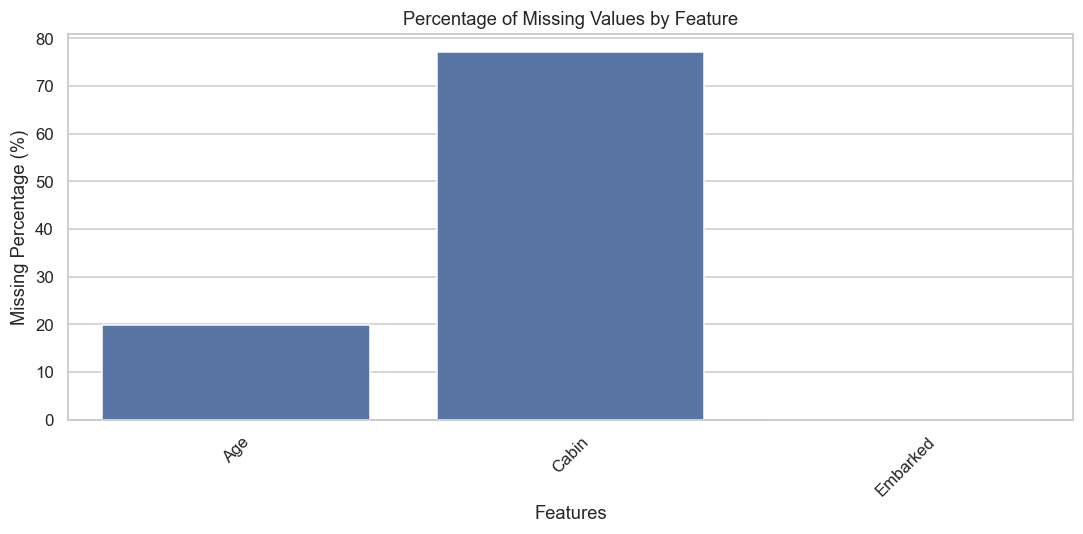

In [4]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_data.index,
    y=missing_data['Missing Percentage']
)

plt.title("Percentage of Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / 'missing_values.png',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation

The dataset contains missing values in three features: Cabin, Age,
and Embarked.

Cabin has the highest proportion of missing values (77.10%),
making direct usage difficult without additional feature engineering.

Age contains 177 missing values (19.87%). These values will
be handled using median imputation.

Embarked contains only 2 missing values (0.22%), which will
be handled using mode imputation.

These preprocessing operations will be performed through
scikit-learn pipelines to avoid data leakage.

## 3. Duplicate Record Analysis

In [5]:
# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

# Check duplicate passenger IDs
duplicate_ids = df['PassengerId'].duplicated().sum()

print("Duplicate Passenger IDs:", duplicate_ids)

Number of duplicate records: 0
Duplicate Passenger IDs: 0


In [6]:
# Count survival categories
survival_counts = df['Survived'].value_counts()

print("Survival Distribution:")
print(survival_counts)

# Calculate percentages
survival_percentage = df['Survived'].value_counts(
    normalize=True
) * 100

print("\nSurvival Percentage:")
print(survival_percentage)

Survival Distribution:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


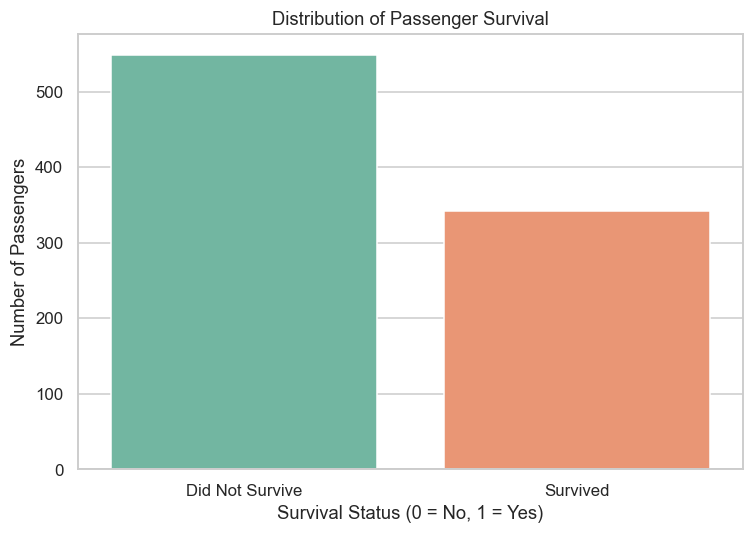

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Survived',
    hue='Survived',
    palette='Set2',
    legend=False
)

plt.title("Distribution of Passenger Survival")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks([0, 1], ['Did Not Survive', 'Survived'])

plt.tight_layout()

plt.savefig(OUTPUT_DIR / 'survival_distribution.png',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Numerical Feature Distribution Analysis

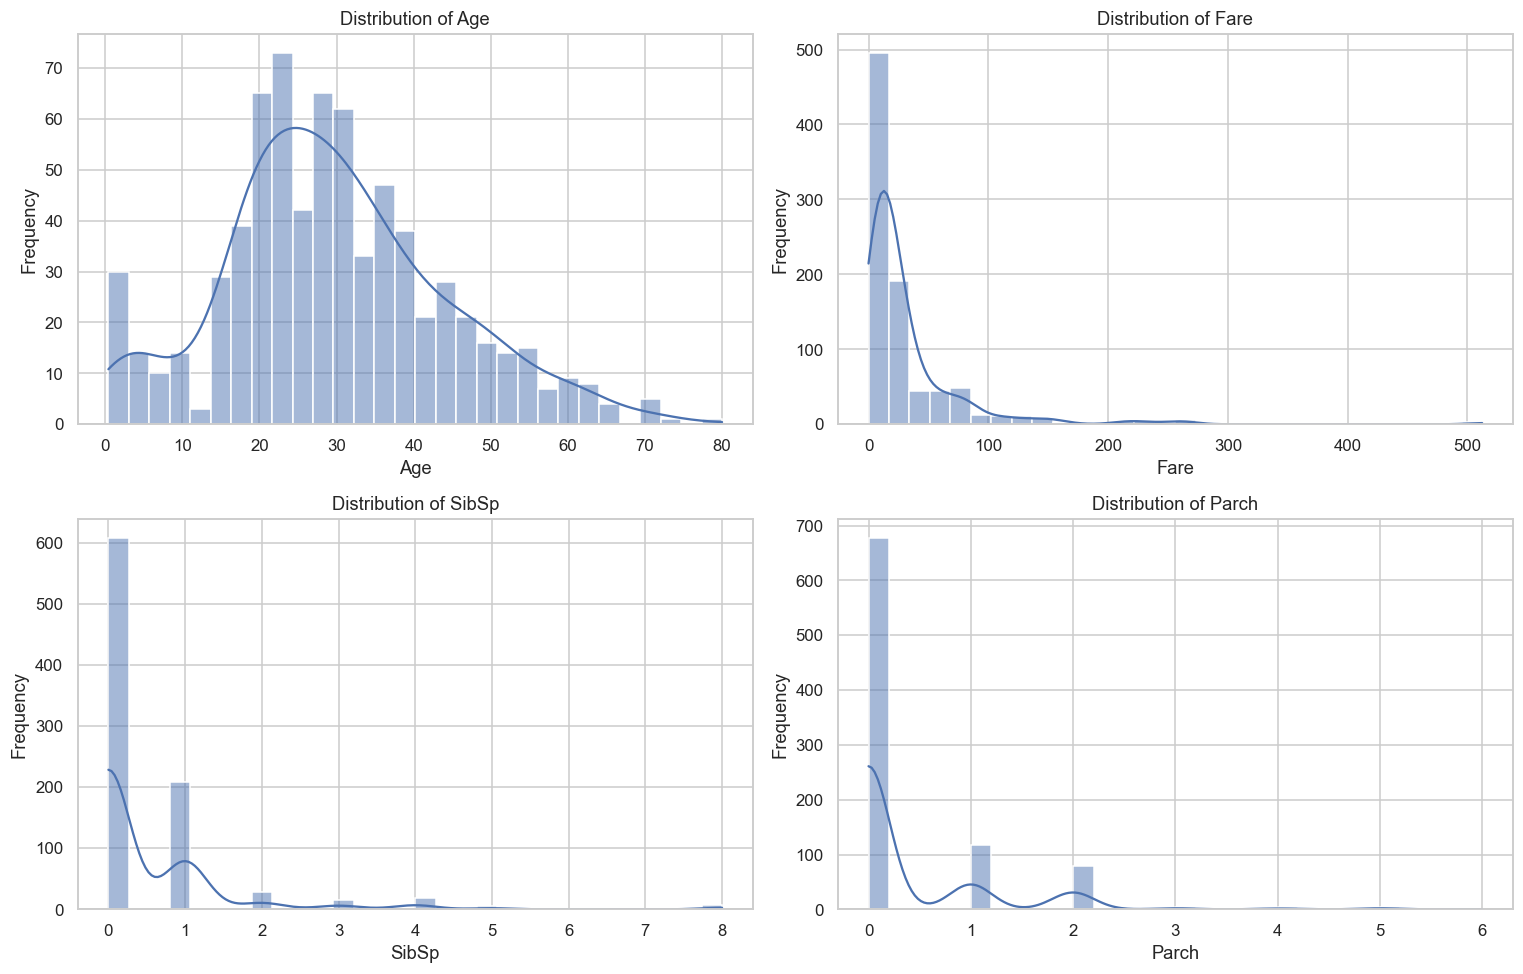

In [8]:
# Select numerical features
numerical_features = ['Age', 'Fare', 'SibSp', 'Parch']

# Plot distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for feature, ax in zip(numerical_features, axes.flatten()):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        bins=30,
        ax=ax
    )

    ax.set_title(f'Distribution of {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')

plt.tight_layout()

plt.savefig(OUTPUT_DIR / 'numerical_distributions.png',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Categorical Feature Analysis

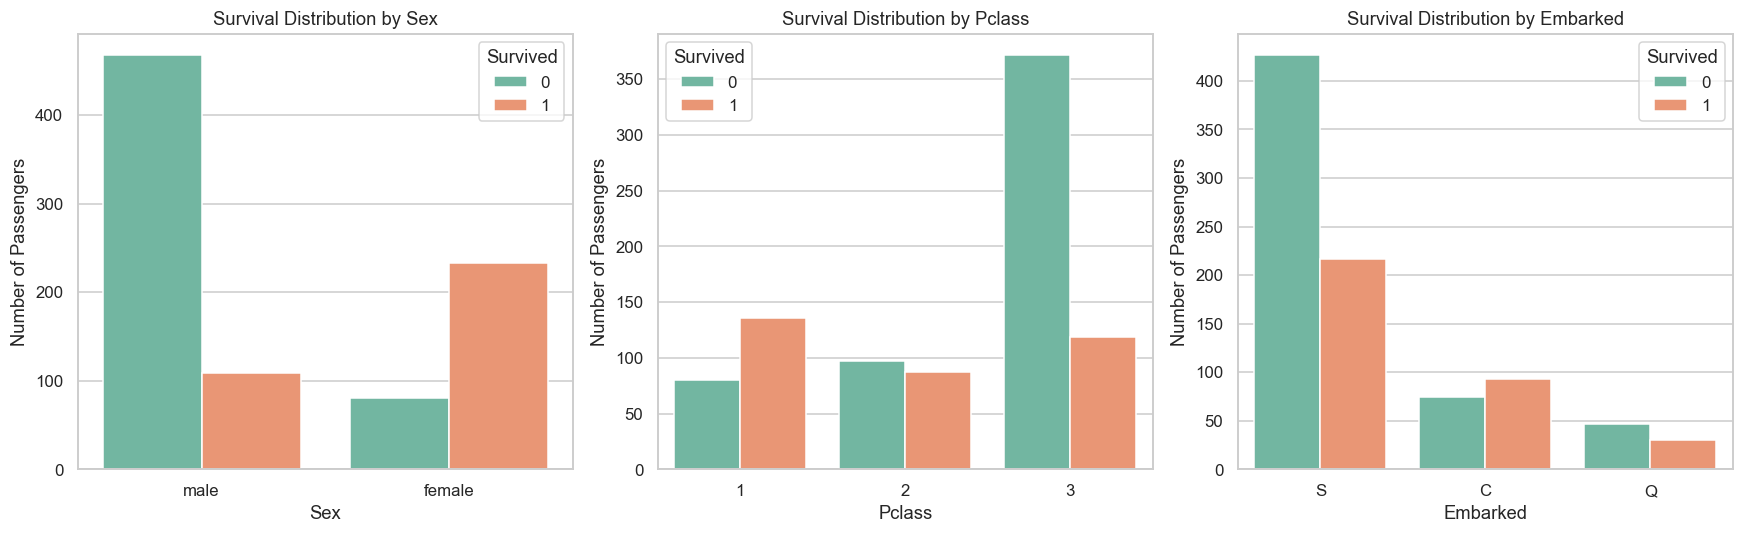

In [9]:
categorical_features = ['Sex', 'Pclass', 'Embarked']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for feature, ax in zip(categorical_features, axes):

    sns.countplot(
        data=df,
        x=feature,
        hue='Survived',
        ax=ax,
        palette='Set2'
    )

    ax.set_title(f'Survival Distribution by {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Number of Passengers')

plt.tight_layout()

plt.savefig(OUTPUT_DIR / 'categorical_survival.png',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Survival rate by categorical features

for feature in categorical_features:

    print(f"\nSurvival Rate by {feature}:")

    survival_rate = (
        df.groupby(feature, observed=True)['Survived']
        .mean()
        .mul(100)
        .round(2)
    )

    display(survival_rate.to_frame(
        name='Survival Rate (%)'
    ))


Survival Rate by Sex:
        Survival Rate (%)
Sex                      
female              74.20
male                18.89

Survival Rate by Pclass:
        Survival Rate (%)
Pclass                   
1                   62.96
2                   47.28
3                   24.24

Survival Rate by Embarked:
          Survival Rate (%)
Embarked                   
C                     55.36
Q                     38.96
S                     33.70


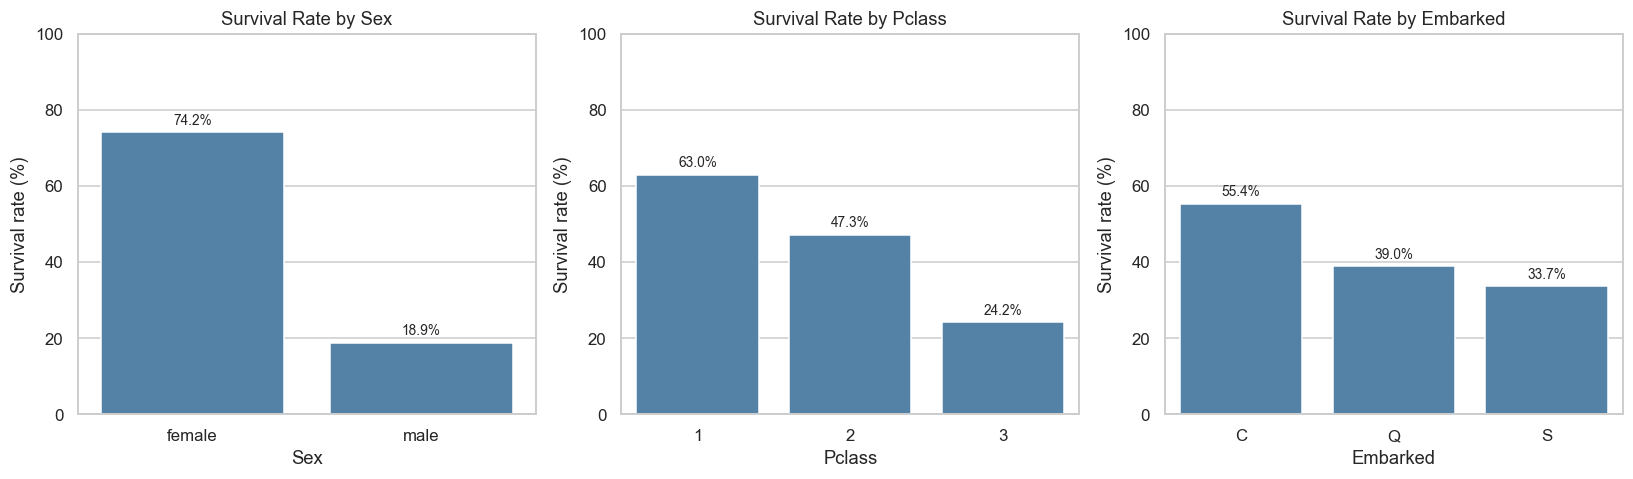

In [11]:
# Plot rates (rather than counts) so group survival propensity is easier to compare.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for feature, ax in zip(categorical_features, axes):
    rates = df.groupby(feature, observed=True)['Survived'].mean().mul(100)
    sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, color='steelblue')
    ax.set_title(f'Survival Rate by {feature}')
    ax.set_xlabel(feature)
    ax.set_ylabel('Survival rate (%)')
    ax.set_ylim(0, 100)
    for patch, value in zip(ax.patches, rates.values):
        ax.annotate(f'{value:.1f}%', (patch.get_x() + patch.get_width()/2, value),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                    textcoords='offset points')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'survival_rates_by_category.png', dpi=300, bbox_inches='tight')
plt.show()


## 6. Correlation Analysis

          Survived  Pclass   Age  SibSp  Parch  Fare
Survived      1.00   -0.34 -0.08  -0.04   0.08  0.26
Pclass       -0.34    1.00 -0.37   0.08   0.02 -0.55
Age          -0.08   -0.37  1.00  -0.31  -0.19  0.10
SibSp        -0.04    0.08 -0.31   1.00   0.41  0.16
Parch         0.08    0.02 -0.19   0.41   1.00  0.22
Fare          0.26   -0.55  0.10   0.16   0.22  1.00


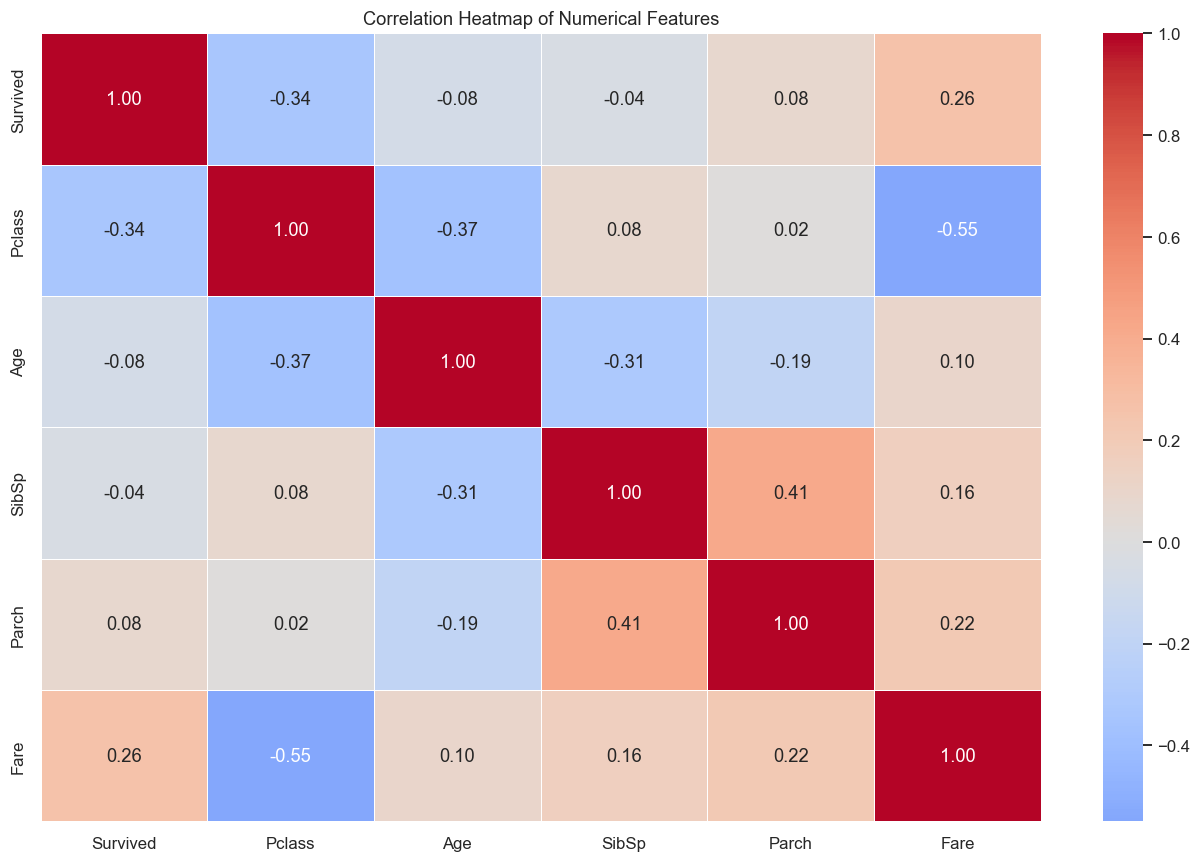

In [12]:
# Select numerical columns
# PassengerId is an identifier, so exclude it from feature correlation analysis.
correlation_data = df.select_dtypes(include=np.number).drop(
    columns=['PassengerId'], errors='ignore'
)

# Calculate Pearson correlation
correlation_matrix = correlation_data.corr()

# Display correlation matrix
display(correlation_matrix.round(2))

# Visualise correlation matrix
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / 'correlation_heatmap.png',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Correlation interpretation

Pearson correlation describes linear association in this sample; it does not establish causation. `Pclass` is ordinal and `Survived` is binary, so these coefficients are descriptive rather than a complete measure of relationship. Pairwise calculations involving `Age` use passengers with observed ages. `PassengerId` is excluded because it is a row identifier.


## 7. Outlier Detection Using IQR

In [13]:
# Features for outlier detection
outlier_features = ['Age', 'Fare', 'SibSp', 'Parch']

outlier_results = []

for feature in outlier_features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    outlier_results.append({
        'Feature': feature,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (
            len(outliers) / len(df)
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

  Feature  Lower Bound  Upper Bound  Outlier Count  Outlier Percentage
0     Age        -6.69        64.81             11                1.23
1    Fare       -26.72        65.63            116               13.02
2   SibSp        -1.50         2.50             46                5.16
3   Parch         0.00         0.00            213               23.91


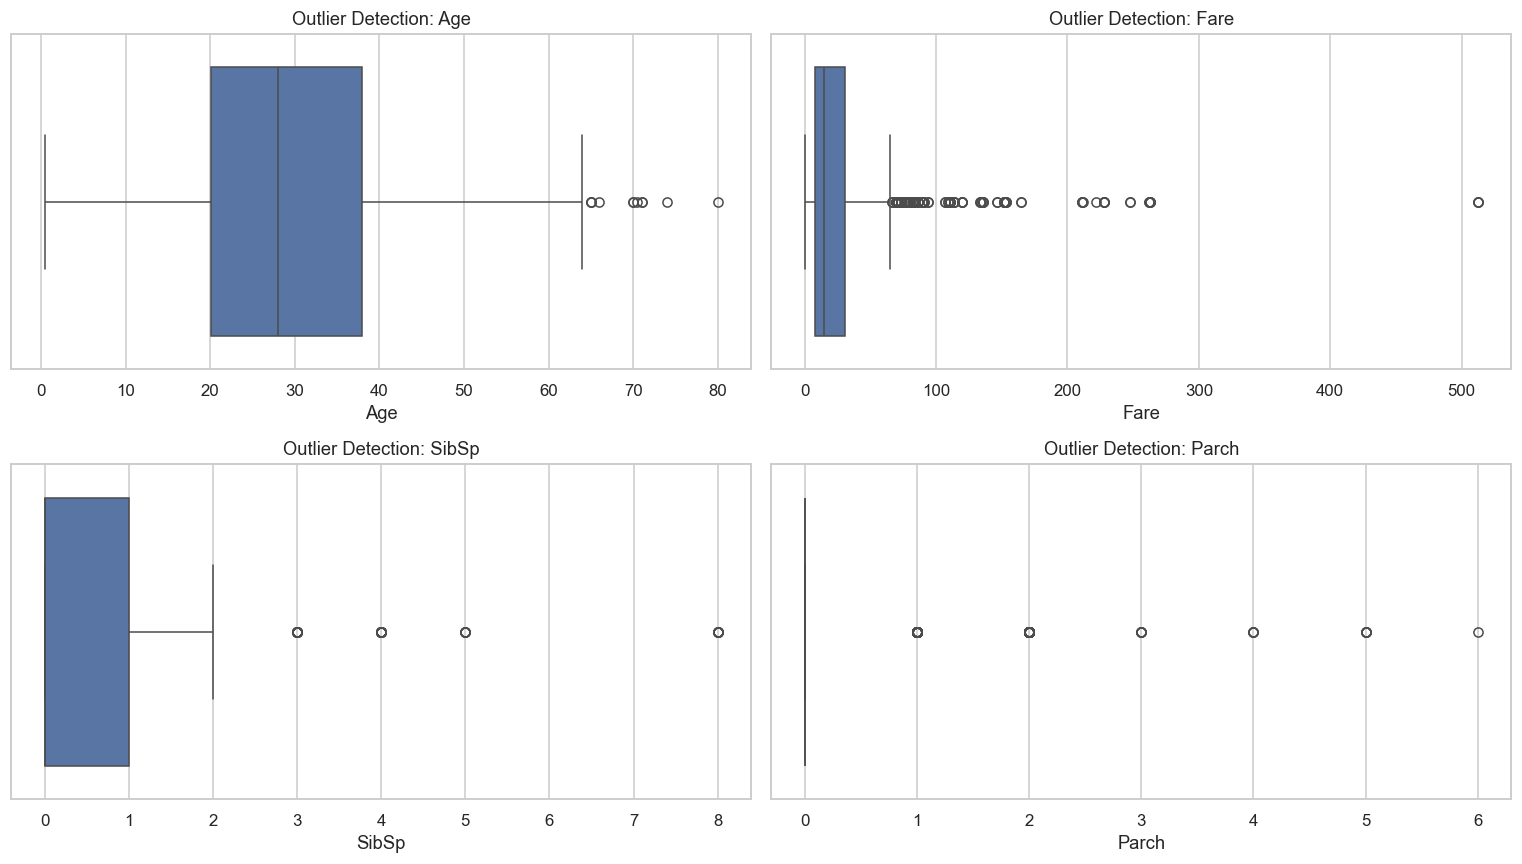

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for feature, ax in zip(outlier_features, axes.flatten()):

    sns.boxplot(
        data=df,
        x=feature,
        ax=ax
    )

    ax.set_title(f'Outlier Detection: {feature}')

plt.tight_layout()

plt.savefig(OUTPUT_DIR / 'outlier_analysis.png',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Outlier interpretation

The IQR rule is used here to flag observations for inspection, not to remove them. In particular, `Parch` has Q1 = Q3 = 0, so the standard upper bound is 0 and every positive value is flagged; this reflects a zero-heavy discrete feature rather than evidence that those passengers are invalid. No observations are removed.


## 8. Feature Engineering

In [15]:
# Create deterministic family features from each passenger's own row
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# Extract the honorific between the comma and period in each passenger name.
# Normalize spelling variants and group uncommon honorifics into one category.
df['Title'] = df['Name'].str.extract(r',\s*([^.]*)\.', expand=False).str.strip()
df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
df['Title'] = df['Title'].where(
    df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']),
    'Rare'
)

print("Title counts:")
print(df['Title'].value_counts().to_string())
print("\nEngineered feature preview:")
display(df[['SibSp', 'Parch', 'FamilySize', 'IsAlone', 'Title']].head(10))


Title counts:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23

Engineered feature preview:
   SibSp  Parch  FamilySize  IsAlone   Title
0      1      0           2        0      Mr
1      1      0           2        0     Mrs
2      0      0           1        1    Miss
3      1      0           2        0     Mrs
4      0      0           1        1      Mr
5      0      0           1        1      Mr
6      0      0           1        1      Mr
7      3      1           5        0  Master
8      0      2           3        0     Mrs
9      1      0           2        0     Mrs


## 9. Baseline Classification Models

This section uses a stratified 70:30 holdout split. Feature construction above is deterministic and uses no target information. Learned imputations, one-hot encoding, and scaling are contained in each model pipeline and are fit using training data only. `PassengerId`, raw `Name`, `Ticket`, and high-missingness `Cabin` are excluded; the engineered `Title` is retained. `FamilySize` and `IsAlone` replace the component counts `SibSp` and `Parch` in the baseline feature set to reduce direct redundancy. No outliers are removed.


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Ensure this modeling section also works after a kernel restart when the EDA
# feature-engineering cell has not yet been run. These row-wise features use no target.
required_engineered_features = {'FamilySize', 'IsAlone', 'Title'}
if not required_engineered_features.issubset(df.columns):
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    df['Title'] = df['Name'].str.extract(r',\s*([^.]*)\.', expand=False).str.strip()
    df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    df['Title'] = df['Title'].where(
        df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']),
        'Rare'
    )

# Separate predictors and target before any learned preprocessing.
feature_columns = ['Pclass', 'Sex', 'Age', 'Fare', 'FamilySize', 'IsAlone',
                   'Embarked', 'Title']
X = df[feature_columns].copy()
y = df['Survived'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print(f'Train rows: {len(X_train)} ({len(X_train)/len(X):.1%})')
print(f'Test rows:  {len(X_test)} ({len(X_test)/len(X):.1%})')
print('Training target proportions:')
print(y_train.value_counts(normalize=True).sort_index().round(4).to_string())
print('Test target proportions:')
print(y_test.value_counts(normalize=True).sort_index().round(4).to_string())

numeric_features = ['Age', 'Fare', 'FamilySize', 'IsAlone']
categorical_features_model = ['Pclass', 'Sex', 'Embarked', 'Title']

numeric_preprocessing = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_preprocessing = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_preprocessing, numeric_features),
    ('categorical', categorical_preprocessing, categorical_features_model)
])

baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5)
}

fitted_models = {}
metric_rows = []
confusion_matrices = {}
for model_name, estimator in baseline_models.items():
    model_pipeline = Pipeline(steps=[
        ('preprocessing', preprocessor),
        ('classifier', estimator)
    ])
    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)
    fitted_models[model_name] = model_pipeline
    metric_rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-score': f1_score(y_test, predictions, zero_division=0)
    })
    confusion_matrices[model_name] = confusion_matrix(y_test, predictions, labels=[0, 1])

baseline_results = pd.DataFrame(metric_rows).set_index('Model')
print('Holdout metrics (positive class = Survived / 1):')
print(baseline_results.round(4).to_string())
for model_name, matrix in confusion_matrices.items():
    print(f'\n{model_name} confusion matrix (rows=true [0,1], columns=predicted [0,1]):')
    print(matrix)


Train rows: 623 (69.9%)
Test rows:  268 (30.1%)
Training target proportions:
Survived
0    0.6164
1    0.3836
Test target proportions:
Survived
0    0.6157
1    0.3843
Holdout metrics (positive class = Survived / 1):
                     Accuracy  Precision  Recall  F1-score
Model                                                     
Logistic Regression    0.8433     0.8081  0.7767    0.7921
Decision Tree          0.7985     0.7579  0.6990    0.7273
KNN (k=5)              0.7799     0.7245  0.6893    0.7065

Logistic Regression confusion matrix (rows=true [0,1], columns=predicted [0,1]):
[[146  19]
 [ 23  80]]

Decision Tree confusion matrix (rows=true [0,1], columns=predicted [0,1]):
[[142  23]
 [ 31  72]]

KNN (k=5) confusion matrix (rows=true [0,1], columns=predicted [0,1]):
[[138  27]
 [ 32  71]]


### Baseline results: interpretation guide

The table and confusion matrices above are computed on the held-out 30% test set. Accuracy should be read alongside precision, recall, and F1 because the classes are not exactly balanced. A false negative is a passenger predicted not to survive who actually survived; a false positive is the reverse. These are baseline estimates from one stratified split, not final model selection evidence. Cross-validation, tuning, ROC/AUC, and advanced ensembles are reserved for the next stage.


## 10. Advanced Models and Hyperparameter Optimisation

Random Forest and Gradient Boosting are added using the same feature set and leakage-safe preprocessing pipeline as the baseline models. A shuffled, stratified 5-fold split is used only within the training partition. Grid search selects parameters by mean F1; ROC-AUC is recorded as a secondary cross-validation score. The held-out test partition is not used for tuning.


In [17]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.base import clone
import json
from sklearn.metrics import roc_auc_score, roc_curve, auc

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_metrics = {'f1': 'f1', 'roc_auc': 'roc_auc'}

random_forest_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=1))
])
gradient_boosting_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

random_forest_grid = {
    'classifier__n_estimators': [150, 300],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}
gradient_boosting_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__max_depth': [2, 3],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

rf_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=random_forest_grid,
    scoring=scoring_metrics,
    refit='f1',
    cv=cv_strategy,
    n_jobs=1,
    return_train_score=False,
    error_score='raise'
)
gb_search = GridSearchCV(
    estimator=gradient_boosting_pipeline,
    param_grid=gradient_boosting_grid,
    scoring=scoring_metrics,
    refit='f1',
    cv=cv_strategy,
    n_jobs=1,
    return_train_score=False,
    error_score='raise'
)

rf_search.fit(X_train, y_train)
gb_search.fit(X_train, y_train)

best_parameters = {
    'Random Forest': rf_search.best_params_,
    'Gradient Boosting': gb_search.best_params_
}
with open(OUTPUT_DIR.parent / 'best_hyperparameters.json', 'w', encoding='utf-8') as params_file:
    json.dump(best_parameters, params_file, indent=2)

print('Random Forest best parameters (selected by 5-fold mean F1):')
print(rf_search.best_params_)
print(f"Best CV F1: {rf_search.best_score_:.4f}; corresponding CV ROC-AUC: {rf_search.cv_results_['mean_test_roc_auc'][rf_search.best_index_]:.4f}")
print('\nGradient Boosting best parameters (selected by 5-fold mean F1):')
print(gb_search.best_params_)
print(f"Best CV F1: {gb_search.best_score_:.4f}; corresponding CV ROC-AUC: {gb_search.cv_results_['mean_test_roc_auc'][gb_search.best_index_]:.4f}")


Random Forest best parameters (selected by 5-fold mean F1):
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 300}
Best CV F1: 0.7617; corresponding CV ROC-AUC: 0.8697

Gradient Boosting best parameters (selected by 5-fold mean F1):
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}
Best CV F1: 0.7706; corresponding CV ROC-AUC: 0.8781


## 11. Cross-Validation and Class-Weight Investigation

Baseline pipelines are re-evaluated with the same 5-fold stratified cross-validation on training data. For the tuned advanced models, the selected grid-search candidates' fold means and standard deviations are reported. Standard deviations use the population convention (`ddof=0`) consistently across five folds. A separate comparison tests `class_weight='balanced'` for Logistic Regression and the tuned Random Forest; weights are not assumed to help and are not selected automatically.


In [18]:
# Baseline CV: cross_validate clones each pipeline and refits preprocessing within each fold.
cv_rows = []
for model_name, model_pipeline in fitted_models.items():
    cv_scores = cross_validate(
        model_pipeline, X_train, y_train,
        cv=cv_strategy, scoring=scoring_metrics, n_jobs=1,
        return_train_score=False
    )
    cv_rows.append({
        'Model': model_name,
        'CV F1 mean': cv_scores['test_f1'].mean(),
        'CV F1 std': cv_scores['test_f1'].std(ddof=0),
        'CV ROC-AUC mean': cv_scores['test_roc_auc'].mean(),
        'CV ROC-AUC std': cv_scores['test_roc_auc'].std(ddof=0)
    })

# GridSearchCV evaluated every candidate on the same folds; report the selected candidate.
for label, search in [('Random Forest (tuned)', rf_search),
                      ('Gradient Boosting (tuned)', gb_search)]:
    idx = search.best_index_
    cv_rows.append({
        'Model': label,
        'CV F1 mean': search.cv_results_['mean_test_f1'][idx],
        'CV F1 std': search.cv_results_['std_test_f1'][idx],
        'CV ROC-AUC mean': search.cv_results_['mean_test_roc_auc'][idx],
        'CV ROC-AUC std': search.cv_results_['std_test_roc_auc'][idx]
    })
cv_summary = pd.DataFrame(cv_rows).set_index('Model')
print('5-fold training cross-validation summary:')
print(cv_summary.round(4).to_string())

# Compare balanced class weights against unweighted Logistic Regression and tuned Random Forest.
weighted_candidates = {
    'Logistic Regression (unweighted)': fitted_models['Logistic Regression'],
    'Logistic Regression (balanced)': clone(fitted_models['Logistic Regression']).set_params(
        classifier__class_weight='balanced'
    ),
    'Random Forest (unweighted)': rf_search.best_estimator_,
    'Random Forest (balanced)': clone(rf_search.best_estimator_).set_params(
        classifier__class_weight='balanced'
    )
}
weight_rows = []
for label, candidate in weighted_candidates.items():
    scores = cross_validate(
        candidate, X_train, y_train,
        cv=cv_strategy, scoring=scoring_metrics, n_jobs=1,
        return_train_score=False
    )
    candidate.fit(X_train, y_train)
    pred = candidate.predict(X_test)
    prob = candidate.predict_proba(X_test)[:, 1]
    weight_rows.append({
        'Model': label,
        'CV F1 mean': scores['test_f1'].mean(),
        'CV F1 std': scores['test_f1'].std(ddof=0),
        'CV ROC-AUC mean': scores['test_roc_auc'].mean(),
        'CV ROC-AUC std': scores['test_roc_auc'].std(ddof=0),
        'Test F1': f1_score(y_test, pred),
        'Test ROC-AUC': roc_auc_score(y_test, prob)
    })
class_weight_comparison = pd.DataFrame(weight_rows).set_index('Model')
print('\nClass-weight experiment (same split and training-only CV):')
print(class_weight_comparison.round(4).to_string())

# Persist tabular outputs in the existing outputs folder.
OUTPUT_DIR.parent.mkdir(parents=True, exist_ok=True)
cv_summary.to_csv(OUTPUT_DIR.parent / 'cross_validation_summary.csv')
class_weight_comparison.to_csv(OUTPUT_DIR.parent / 'class_weight_comparison.csv')


5-fold training cross-validation summary:
                           CV F1 mean  CV F1 std  CV ROC-AUC mean  CV ROC-AUC std
Model                                                                            
Logistic Regression            0.7460     0.0369           0.8581          0.0251
Decision Tree                  0.6987     0.0420           0.7566          0.0368
KNN (k=5)                      0.7367     0.0168           0.8430          0.0266
Random Forest (tuned)          0.7617     0.0313           0.8697          0.0272
Gradient Boosting (tuned)      0.7706     0.0275           0.8781          0.0233

Class-weight experiment (same split and training-only CV):
                                  CV F1 mean  CV F1 std  CV ROC-AUC mean  CV ROC-AUC std  Test F1  Test ROC-AUC
Model                                                                                                          
Logistic Regression (unweighted)      0.7460     0.0369           0.8581          0.0251   0.7921   

## 12. Held-Out Model Comparison and ROC Curves

Each selected model is evaluated once on the untouched test partition. ROC curves use predicted probabilities and AUC summarizes ranking quality across thresholds. These held-out scores describe this split; model selection and parameter tuning remain based on training-only cross-validation.


Consolidated comparison (test metrics plus training CV F1):
                           Accuracy  Precision  Recall  F1-score  ROC-AUC  CV F1 mean  CV F1 std
Model                                                                                           
Logistic Regression          0.8433     0.8081  0.7767    0.7921   0.8783      0.7460     0.0369
Decision Tree                0.7985     0.7579  0.6990    0.7273   0.7812      0.6987     0.0420
KNN (k=5)                    0.7799     0.7245  0.6893    0.7065   0.8520      0.7367     0.0168
Random Forest (tuned)        0.8358     0.8315  0.7184    0.7708   0.8742      0.7617     0.0313
Gradient Boosting (tuned)    0.8172     0.8068  0.6893    0.7435   0.8721      0.7706     0.0275

Logistic Regression confusion matrix (rows=true [0,1], columns=predicted [0,1]):
[[146  19]
 [ 23  80]]

Decision Tree confusion matrix (rows=true [0,1], columns=predicted [0,1]):
[[142  23]
 [ 31  72]]

KNN (k=5) confusion matrix (rows=true [0,1], columns=pre

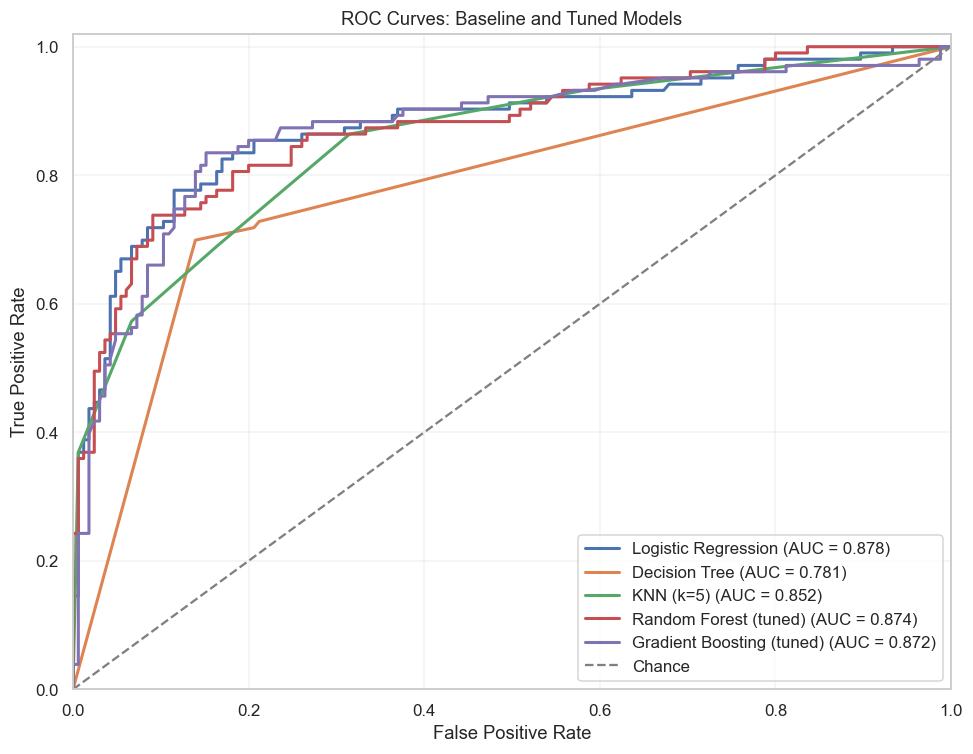

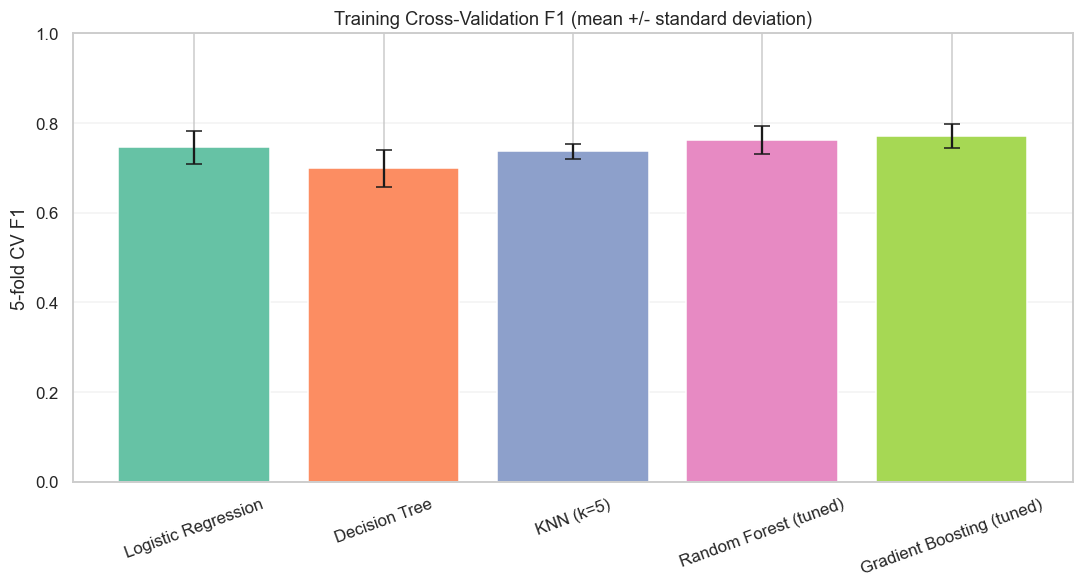

In [19]:
selected_models = {
    'Logistic Regression': fitted_models['Logistic Regression'],
    'Decision Tree': fitted_models['Decision Tree'],
    'KNN (k=5)': fitted_models['KNN (k=5)'],
    'Random Forest (tuned)': rf_search.best_estimator_,
    'Gradient Boosting (tuned)': gb_search.best_estimator_
}
comparison_rows = []
test_confusion_matrices = {}
fig, ax = plt.subplots(figsize=(9, 7))
for model_name, model_pipeline in selected_models.items():
    predictions = model_pipeline.predict(X_test)
    probabilities = model_pipeline.predict_proba(X_test)[:, 1]
    test_confusion_matrices[model_name] = confusion_matrix(y_test, predictions, labels=[0, 1])
    test_auc = roc_auc_score(y_test, probabilities)
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    ax.plot(fpr, tpr, linewidth=2, label=f'{model_name} (AUC = {test_auc:.3f})')
    comparison_rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-score': f1_score(y_test, predictions, zero_division=0),
        'ROC-AUC': test_auc
    })
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='False Positive Rate',
       ylabel='True Positive Rate', title='ROC Curves: Baseline and Tuned Models')
ax.legend(loc='lower right', frameon=True)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'roc_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

test_comparison = pd.DataFrame(comparison_rows).set_index('Model')
model_comparison = test_comparison.join(cv_summary[['CV F1 mean', 'CV F1 std']])
print('Consolidated comparison (test metrics plus training CV F1):')
print(model_comparison.round(4).to_string())
model_comparison.to_csv(OUTPUT_DIR.parent / 'model_comparison.csv')

confusion_matrix_rows = []
for model_name, matrix in test_confusion_matrices.items():
    tn, fp, fn, tp = matrix.ravel()
    confusion_matrix_rows.append({
        'Model': model_name,
        'True negative': tn,
        'False positive': fp,
        'False negative': fn,
        'True positive': tp
    })
    print(f'\n{model_name} confusion matrix (rows=true [0,1], columns=predicted [0,1]):')
    print(matrix)
confusion_matrix_table = pd.DataFrame(confusion_matrix_rows).set_index('Model')
confusion_matrix_table.to_csv(OUTPUT_DIR.parent / 'confusion_matrices.csv')

# Plot fold-average F1 with standard-deviation error bars for all five models.
plot_data = cv_summary.loc[list(selected_models.keys())]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(plot_data.index, plot_data['CV F1 mean'],
       yerr=plot_data['CV F1 std'], capsize=5, color=sns.color_palette('Set2', len(plot_data)))
ax.set_ylabel('5-fold CV F1')
ax.set_title('Training Cross-Validation F1 (mean +/- standard deviation)')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=20)
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'cross_validation_f1_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


## 13. Tree-Based Feature Importance

Impurity-based feature importance is extracted from the tuned Random Forest and Gradient Boosting pipelines after one-hot encoding. The ranking helps describe which encoded predictors contribute most to the fitted trees; it is not causal evidence and can distribute importance across correlated or related features.


Ranked encoded feature importance:
                  Feature  Random Forest importance  Gradient Boosting importance  Random Forest rank  Gradient Boosting rank  Mean rank
            numeric__Fare                    0.1864                        0.1590                   1                       2        1.5
    categorical__Title_Mr                    0.1449                        0.2596                   3                       1        2.0
             numeric__Age                    0.1527                        0.1117                   2                       4        3.0
    categorical__Sex_male                    0.1137                        0.1561                   4                       3        3.5
  categorical__Sex_female                    0.1031                        0.0968                   5                       5        5.0
      numeric__FamilySize                    0.0699                        0.0852                   6                       6        6.0
    ca

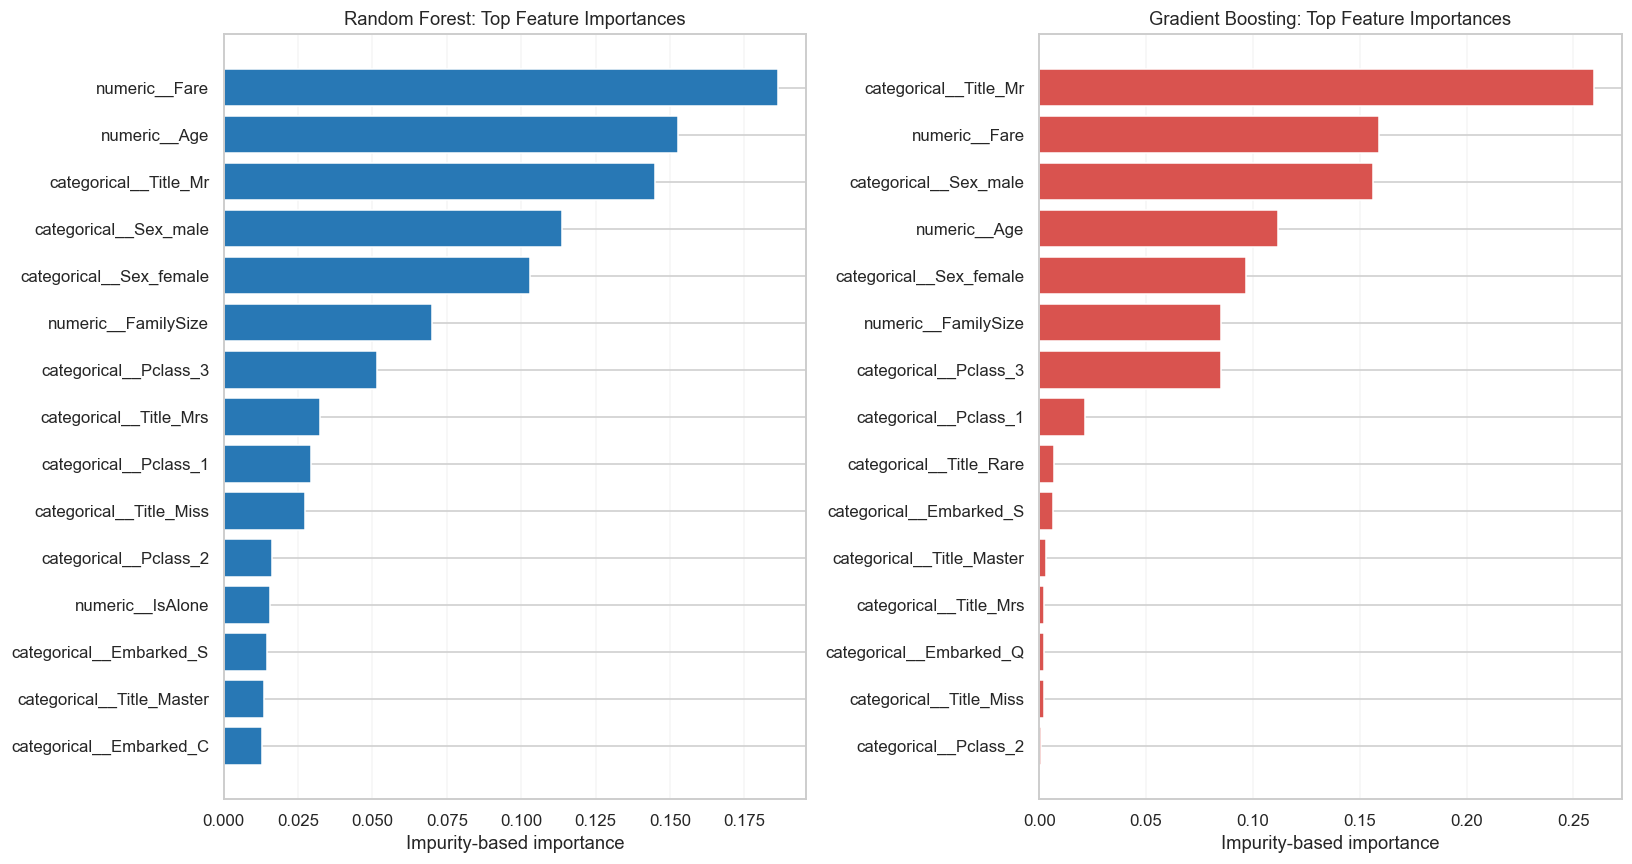

In [20]:
rf_feature_names = rf_search.best_estimator_.named_steps['preprocessing'].get_feature_names_out()
gb_feature_names = gb_search.best_estimator_.named_steps['preprocessing'].get_feature_names_out()
rf_importances = rf_search.best_estimator_.named_steps['classifier'].feature_importances_
gb_importances = gb_search.best_estimator_.named_steps['classifier'].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': rf_feature_names,
    'Random Forest importance': rf_importances,
    'Gradient Boosting importance': gb_importances
})
feature_importance['Random Forest rank'] = feature_importance['Random Forest importance'].rank(
    ascending=False, method='min'
).astype(int)
feature_importance['Gradient Boosting rank'] = feature_importance['Gradient Boosting importance'].rank(
    ascending=False, method='min'
).astype(int)
feature_importance['Mean rank'] = feature_importance[
    ['Random Forest rank', 'Gradient Boosting rank']
].mean(axis=1)
feature_importance = feature_importance.sort_values('Mean rank').reset_index(drop=True)
print('Ranked encoded feature importance:')
print(feature_importance.round(4).to_string(index=False))
feature_importance.to_csv(OUTPUT_DIR.parent / 'feature_importance.csv', index=False)

# Visualize the top encoded features for each tree model.
top_n = 15
rf_top = feature_importance.nsmallest(top_n, 'Random Forest rank').sort_values(
    'Random Forest importance'
)
gb_top = feature_importance.nsmallest(top_n, 'Gradient Boosting rank').sort_values(
    'Gradient Boosting importance'
)
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
axes[0].barh(rf_top['Feature'], rf_top['Random Forest importance'], color='#2878B5')
axes[0].set_title('Random Forest: Top Feature Importances')
axes[0].set_xlabel('Impurity-based importance')
axes[1].barh(gb_top['Feature'], gb_top['Gradient Boosting importance'], color='#D9534F')
axes[1].set_title('Gradient Boosting: Top Feature Importances')
axes[1].set_xlabel('Impurity-based importance')
for ax in axes: ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'tree_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()


### Provisional Model Selection and Interpretation

**Logistic Regression is the provisional choice** under the requested held-out criteria. On the 268-row test partition it achieved accuracy 0.8433, recall 0.7767, F1 0.7921, and ROC-AUC 0.8783. Random Forest achieved 0.8358, 0.7184, 0.7708, and 0.8742 respectively; Gradient Boosting achieved 0.8172, 0.6893, 0.7435, and 0.8721. Random Forest had higher precision (0.8315 versus Logistic Regression's 0.8081), which may matter if false positives carry more cost.

This test ranking differs from training-only cross-validation: Gradient Boosting had the highest selected-model CV F1 (0.7706 ? 0.0275) and CV ROC-AUC (0.8781 ? 0.0233), compared with Logistic Regression's 0.7460 ? 0.0369 and 0.8581 ? 0.0251. The disagreement indicates model ranking uncertainty across partitions. Since the provisional choice considers test scores, the test set is no longer a fully untouched estimate for that model-selection decision; retain the choice as provisional and report this limitation.

### Feature Importance Interpretation

Fare ranked first for Random Forest (importance 0.1864); `Title_Mr` ranked first for Gradient Boosting (0.2596). Age, sex indicators, FamilySize, and passenger class also ranked highly. These impurity-based importances describe how the fitted tree models used encoded features, not causal effects. Title and sex are related, so their importances may be distributed across associated indicators.

### Class Imbalance and Business Insights

The target proportions are 61.62% did not survive and 38.38% survived. This is a moderate class difference, not an extreme imbalance. Balanced class weights did not consistently help: they lowered Logistic Regression's CV and test F1; Random Forest's CV F1 rose slightly while its test F1 and test ROC-AUC fell. The unweighted models remain the main comparison, and no SMOTE was used.

In this historical sample, survival rates varied substantially by sex and passenger class, with fare, age, family size, and title also contributing to model predictions. For a historical safety analysis, these patterns can help identify groups that may have faced unequal access to evacuation or assistance. They should not be treated as causal evidence or as a current passenger-risk tool; modern safety planning should prioritize equitable access and use relevant contemporary evidence.

### Limitations and Future Checks

The data contain only 891 historical passengers, and one stratified holdout split can produce variable results. Grid-search CV scores are selection scores and can be optimistic because the best candidate is chosen using those same folds. The test results are also now part of the provisional model choice. Before making strong generalization claims, validate the provisional choice with nested cross-validation or a genuinely new independent dataset. Other useful next checks are threshold selection tied to the cost of missed survivors, subgroup error review, probability calibration, and permutation importance. No additional model family is needed to complete this stage.
